# Dry 10 days in May

### Loading packages
Packages used to run the MODFLOW 6 groundwater model. 

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import flopy
from flopy.utils.gridgen import Gridgen
import pandas as pd
import pyemu
import shutil
import numpy as np
flopy.__version__

'3.11.0'

### Plots of input data: GHB (General Head Boundary) and CHD (Constant Head or Time-Variant Specified-Head Boundary)

Hourly water level data at sea and the mangrove are set as the boundaries in the MODFLOW model. The sea water levels are assigned to the CHD boundary. The mangrove water levels are assigned to the GHB boundray. 

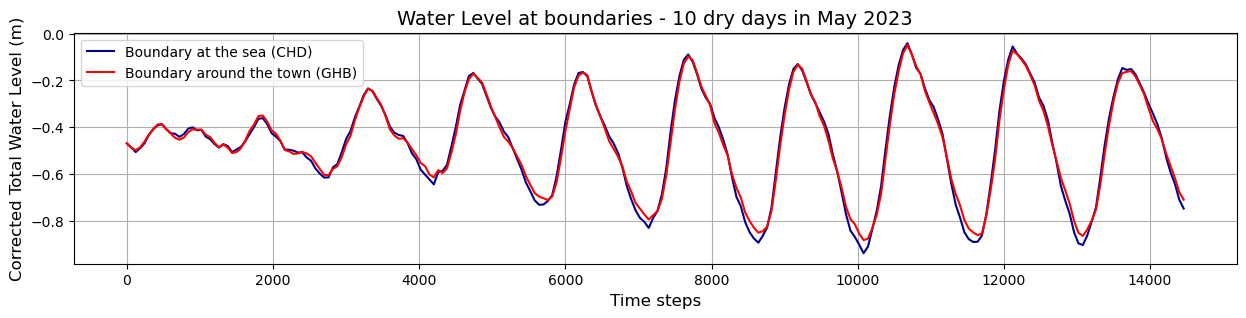

In [2]:
twl_may = pd.read_csv(r"C:\SAN_FELIPE\SAN_FELIPE\forcing\CHD&GHB\05_Corrected_total_water_level_2023_may.csv")
plt.figure(figsize=(15, 3))

plt.plot(twl_may["PASO"]*60, twl_may["MAR"], label="Boundary at the sea (CHD)", color='darkblue')
plt.plot(twl_may["PASO"]*60, twl_may["COL1"], label="Boundary around the town (GHB)", color='red')


plt.xlabel("Time steps", fontsize=12)
plt.ylabel("Corrected Total Water Level (m)", fontsize=12)
plt.title("Water Level at boundaries - 10 dry days in May 2023", fontsize=14)
plt.legend()
plt.grid(True)

output_folder = r"C:\MDP\Figuren MODFLOW\Dry"
output_path = os.path.join(output_folder, "water_levels_may_2023.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()


### Plots of input data: Precipitation

Hourly precipitation at San Felipe is retrieved from location lon 21,5 and lat -88,25. 

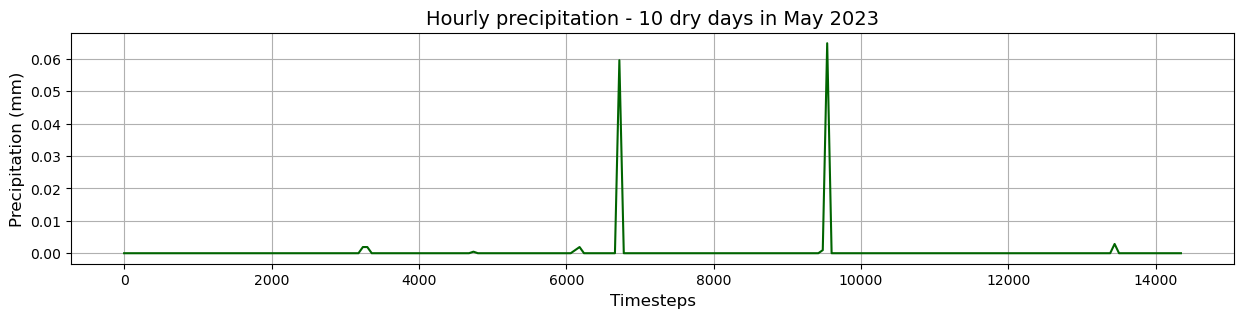

In [3]:
precip_may = pd.read_excel(r"C:\SAN_FELIPE\SAN_FELIPE\forcing\RCH\Precipitation_dry_may.xlsx")

plt.figure(figsize=(15, 3))
plt.plot(precip_may.index * 60, precip_may["tp_mm"], color='darkgreen')
plt.xlabel("Timesteps", fontsize=12)
plt.ylabel("Precipitation (mm)", fontsize=12)
plt.title("Hourly precipitation - 10 dry days in May 2023", fontsize=14)
plt.grid(True)

output_folder = r"C:\MDP\Figuren MODFLOW\Dry"
output_path = os.path.join(output_folder, "precipitation_may_2023.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

## Modelmuse
ModelMuse is a graphical interface used to generate spatial and temporal discretization independent of the data. The spatial geometry is done in MODELMUSE and its outputs are loaded in here. In second cell a list of all packages from MODELMUSE are printed

In [4]:
sim_source = r"C:\SAN_FELIPE\SAN_FELIPE\modelMuse_output"
sim_name = 'modflow'
exe_path = os.path.join(os.path.dirname(os.getcwd()), 'exe','mf6.exe') 
sim6 = flopy.mf6.MFSimulation.load(sim_name, exe_name=exe_path, sim_ws=sim_source) 

loading simulation...
  loading simulation name file...
  loading tdis package...
  loading model gwf6...
    loading package dis...
    loading package ic...
    loading package npf...
    loading package oc...
    loading package chd...
    loading package rch...
  loading solution package modflow...


In [5]:
gwf = sim6.get_model()
gwf.get_package_list()

['DIS', 'IC', 'NPF', 'OC', 'CHD-1', 'RCH-1']

### Model workspace
A workspace is created in which all the output files of the MODFLOW groundwater simulation model are placed. The simulation is run in the same folder/workspace. 

In [6]:
workspace= os.path.join(os.getcwd(), 'model_dry')     
model_name = 'SAN_FELIPE'

In [7]:
sim = flopy.mf6.MFSimulation(sim_name=model_name, version="mf6", exe_name=exe_path, sim_ws=workspace)

In [8]:
mf = flopy.mf6.ModflowGwf(sim, modelname=model_name, model_nam_file=f"{model_name}.nam")
mf.name_file.save_flows = True

### Hydraulic conductivity and conductance

The hydraulic conductivity is given below. The hydraulic conductivity is given in m/s and transformed to m/min. 

The conductance is used at the GHB boundary. The model only has one layer in z-direction (6m). The distance to the mangrove water level source is set to 1000 m. The width of the grid cells is 5 m. 

In [9]:
# Parameters for calibration
k = 5.54e-4 * 60 #m/min

# conductance uses in GHB. cond = K * (W*L/D), where A is the area of the cell (5(cell size)*6(depth aquifer)) and L is the length of the cell (5m).
cond2 = k * ((5*6)/1000)

### Time discretization (TDIS)
The model is run in minutes with time steps of 60 minutes. Each stress period is 60 minutes and within one stress-period there are 5 time steps. A steady state run is included (the first run).

In [10]:
df = pd.read_csv(r"C:\SAN_FELIPE\SAN_FELIPE\forcing\CHD&GHB\05_Corrected_total_water_level_2023_may.csv")
num_records = len(df)  
print(num_records)

pname = 'tdis'
time_units = 'minutes'
len_sptran = 60.0 
int_tran = 5      

include_steady_period = True 

if include_steady_period:
    nper = num_records  
    perlen = np.ones(nper) * len_sptran
    nstp = np.ones(nper, dtype=int) * int_tran
    tsmult = np.ones(nper)
    
    
    perlen[0] = 1.0  
    nstp[0] = 1
else:
    nper = num_records  
    
    perlen = np.ones(nper) * len_sptran
    nstp = np.ones(nper, dtype=int) * int_tran
    tsmult = np.ones(nper)


perioddata = list(zip(perlen, nstp, tsmult))

tdis = flopy.mf6.ModflowTdis(
    sim, 
    pname=pname, 
    time_units=time_units, 
    nper=nper, 
    perioddata=perioddata
)
print(nper)

242
242


### Iterative Model Solver (IMS) 
This package helps with convergence of MODFLOW formulas.

In [11]:


ims6 = sim6.get_package('ims') 
pname = 'ims'
print_option = ims6.print_option.get_data()
complexity = None  
outer_dvclose = 0.01 
outer_maximum = 150 
under_relaxation = None
inner_maximum = 250 
inner_dvclose = 0.001 

linear_acceleration = 'cg' 
scaling_method = None 
reordering_method = None 
relaxation_factor = 0.97 


ims = flopy.mf6.ModflowIms(sim, pname=pname, print_option=print_option, complexity=complexity, outer_dvclose=outer_dvclose, outer_maximum=outer_maximum, 
                           under_relaxation=under_relaxation, inner_maximum=inner_maximum, inner_dvclose=inner_dvclose, 
                           linear_acceleration=linear_acceleration, scaling_method=scaling_method, reordering_method=reordering_method, 
                           relaxation_factor=relaxation_factor)

sim.register_ims_package(ims, [mf.name])

### Spatial Discretization (DIS)
In this package, the ModelMuse outputs are used.

In [12]:
dis6 = gwf.get_package('dis')
pname = 'dis'
length_units = dis6.length_units.get_data()
nogrb = dis6.nogrb.get_data()
xorigin = dis6.xorigin.get_data()
yorigin = dis6.yorigin.get_data()
angrot = dis6.angrot.get_data()
nlay = dis6.nlay.get_data()
nrow = dis6.nrow.get_data()
ncol = dis6.ncol.get_data()
delr = dis6.delr.get_data()
delc = dis6.delc.get_data()
top = dis6.top.get_data()
botm = dis6.botm.get_data()
idomain = dis6.idomain.get_data()


dis = flopy.mf6.ModflowGwfdis(mf, pname=pname, length_units=length_units, nogrb=nogrb, xorigin=xorigin, yorigin=yorigin, angrot=angrot, nlay=nlay, 
                              nrow=nrow, ncol=ncol, delr=delr, delc=delc, top=top, botm=botm, idomain=idomain)

### Initial condition (IC)
For the initital water head, the top elevation of the aquifer is used.

In [13]:
import scipy

h_inicial = top

ic6 = gwf.get_package('ic')
pname = 'ic'
strt = h_inicial

ic = flopy.mf6.ModflowGwfic(mf, pname=pname, strt=strt)

### Node property flow (NPF)
This package describes how water flows from one cell to the other, based on the hydraulic conductivity.

In [14]:
npf6 = gwf.get_package('npf')
pname = 'npf'
save_flows = npf6.save_flows.get_data()
save_specific_discharge = npf6.save_specific_discharge.get_data()
icelltype = 1 
k = k
k22 = k
k33 = k/10


npf = flopy.mf6.ModflowGwfnpf(mf, pname=pname,save_flows=save_flows, save_specific_discharge=save_specific_discharge, icelltype=icelltype, k=k,
                              k22=k22, k33=k33)

### Observation (OBS) package 
Here, different locations are added as observation points. This creates a file with heads over time for each observation point, which is usefull for further processing.

In [15]:
pname = 'obs'
digits = 8
continous = {model_name+'.ob_gw_out_head.csv':[('P1', 'head', (0, 38, 96)), ('P2', 'head', (0, 93, 81)), ('P3', 'head', (0, 178, 64)),
                                              ('P4', 'head', (0, 88, 36)), ('P5', 'head', (0, 108, 132))]}
                                              

obs = flopy.mf6.ModflowUtlobs(mf, pname=pname, digits=digits, continuous=continous)

### Storage (STO) package 
This package is used in transient models to specify the storage properties of the cells. Since an unconfined aquifer is simulateed, the specific yield is most important

In [16]:
steady_state = {e:True for e in range(0,1)} 

transient = {e:True for e in range(1,nper)} 
iconvert = 1  
sy = 0.26 
ss = 1.5e-4 / 0.3 #Value taken from Lohan (1972)

sto = flopy.mf6.modflow.mfgwfsto.ModflowGwfsto(mf, steady_state=steady_state, transient=transient, iconvert=iconvert, sy=sy, ss=ss)

### Output control (OC) package
This package saves the output of the modelling.

In [17]:
oc6 = gwf.get_package('oc')
pname = 'oc'
budget_filerecord = model_name + '.cbc'
head_filerecord = model_name + '.bhd'
saverecord = {e:[("HEAD", 'LAST'), ("BUDGET", 'LAST')]for e in range(nper)}
printrecord = {e:[("HEAD", "LAST"), ('BUDGET','LAST')] for e in range(nper)}


oc = flopy.mf6.ModflowGwfoc(mf, pname=pname, budget_filerecord=budget_filerecord, head_filerecord=head_filerecord, saverecord=saverecord, 
                            printrecord=printrecord)

### Call Gridgen

In [18]:
gridgen_exe = os.path.join(os.getcwd(), 'gridgen_x64.exe')
g = Gridgen(dis, model_ws=workspace, exe_name = gridgen_exe)
g.build()

c:\Anaconda\Lib\site-packages\flopy\utils\gridgen.py:232: UserWarning: Supplying a dis object is deprecated, and support will be removed in version 3.3.7. Please supply StructuredGrid.


### Collect data for boundary conditions CHD and GHB

In [19]:
file_path = r"C:\SAN_FELIPE\SAN_FELIPE\forcing\CHD&GHB\05_Corrected_total_water_level_2023_may.csv"
h_bound = pd.read_csv(file_path, index_col=0, header=0)
h_bound.info()

<class 'pandas.core.frame.DataFrame'>
Index: 242 entries, 0 to 241
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MAR     242 non-null    float64
 1   COL1    242 non-null    float64
dtypes: float64(2)
memory usage: 5.7 KB


### The boundary condition at the sea side (total water head north west of San Felipe) CHD package
In this cell values are assigned to the boundaries based on input data for total water head at the sea.

In [20]:
pname = 'chd'

chd_path = os.path.join(os.getcwd(), 'shapes')


chd_intersect = g.intersect(chd_path+'/Coastline', 'line', 0) 
chd_unique = np.unique(chd_intersect.nodenumber) 

chd_rec = {} 

for sp in range(0,1): 
    chd_rec.setdefault(sp,[]) 
    h_chd = h_bound['MAR'][sp].item() 
    for ix in np.arange(chd_unique.shape[0]): 
        [(l,i,j)] = mf.modelgrid.get_lrc([chd_unique[ix]])
        if idomain[(l,i,j)] == 1: 
            chd_rec[sp].append(((l, i, j), h_chd)) 

for sp in range(1,nper): 
    chd_rec.setdefault(sp,[]) 
    h_chd = h_bound['MAR'][sp].item() 
    for ix in np.arange(chd_unique.shape[0]): 
        [(l,i,j)] = mf.modelgrid.get_lrc([chd_unique[ix]]) 
        if idomain[(l,i,j)] == 1: 
            chd_rec[sp].append(((l, i, j), h_chd)) 
            

maxbound = len(chd_rec[sp]) 

chd = flopy.mf6.ModflowGwfchd(mf, pname=pname, maxbound=maxbound, stress_period_data=chd_rec, save_flows=True)

### The boundary condition around the town (total water head east in mangrove used) GHB package
In this cell values are assigned to the boundaries based on input data for total water head in the lagoon area.

In [21]:
pname = 'ghb'

ghb_path = os.path.join(os.getcwd(), 'shapes') 

ghb_rec = {} 

ghb_intersect = g.intersect(ghb_path+'/Closedsystem1', 'line', 0)
ghb_unique = np.unique(ghb_intersect.nodenumber)

cond = cond2 

for sp in range(0,1):
    ghb_rec.setdefault(sp,[])
    h_ghb = h_bound['COL1'][sp].item()
    for ix in np.arange(ghb_unique.shape[0]): 
        [(l,i,j)] = mf.modelgrid.get_lrc([ghb_unique[ix]])
        if idomain[(l,i,j)] == 1:
            ghb_rec[sp].append(((l, i, j), h_ghb, cond))

for sp in range(1,nper):
    ghb_rec.setdefault(sp,[])
    h_ghb = h_bound['COL1'][sp].item()
    for ix in np.arange(ghb_unique.shape[0]): 
        [(l,i,j)] = mf.modelgrid.get_lrc([ghb_unique[ix]])
        if idomain[(l,i,j)] == 1:
            ghb_rec[sp].append(((l, i, j), h_ghb, cond))

maxbound = len(ghb_rec[sp]) 

ghb = flopy.mf6.ModflowGwfghb(mf, pname=pname, maxbound=maxbound, stress_period_data=ghb_rec, save_flows=True)

### Plot of the boundary condition
Both boundaries are plotted within the domain. Also, the different observation points are shown.

C:\Users\Davida van Krimpen\AppData\Local\Temp\ipykernel_17168\2995073855.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


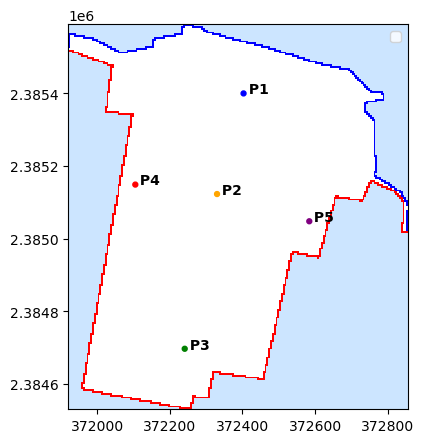

In [22]:
fig1, ax= plt.subplots(figsize=(30,5))
mapview = flopy.plot.PlotMapView(model=mf)
pltibd= mapview.plot_ibound(color_noflow='#CCE5FF')
pltchd = mapview.plot_bc('CHD', color='blue')
pltghb = mapview.plot_bc('GHB', color='red')

P1 = [372403, 2385400]
P2 = [372330, 2385123]
P3 = [372241, 2384697]
P4 = [372105, 2385149]
P5 = [372584, 2385048]
x_locs = [P1[0], P2[0], P3[0], P4[0], P5[0]]

y_locs = [P1[1], P2[1], P3[1], P4[1], P5[1]]
c = ['blue', 'orange', 'green', 'red', 'purple']
ax.scatter(x_locs, y_locs, color=c, s=50, marker=".", zorder=5)

for i, (x, y) in enumerate(zip(x_locs, y_locs)):
    ax.annotate(
        f" P{i+1}", (x, y), fontsize=10, fontweight="bold", color="black" )

plt.legend(loc="upper right")

In [23]:
results = []

for x, y in zip(x_locs, y_locs):
    row, col = mf.modelgrid.intersect(x, y)
    dx = mf.modelgrid.delr[col]
    dy = mf.modelgrid.delc[row]
    
    results.append({
        'x': x,
        'y': y,
        'row': row,
        'col': col
    })

df_results = pd.DataFrame(results)
print(df_results)

        x        y  row  col
0  372403  2385400   38   96
1  372330  2385123   93   81
2  372241  2384697  178   64
3  372105  2385149   88   36
4  372584  2385048  108  132


### Recharge package (RCH)
In this, a percentage (40 percent) of the rainfall is spread over the domain.

In [24]:
Cr = 0.40  

df_P = pd.read_excel(r"C:\SAN_FELIPE\SAN_FELIPE\forcing\RCH\Precipitation_dry_may.xlsx")

tp_hourly_mm = df_P["tp_mm"].values
  
print(f'length tp_hourly {len(tp_hourly_mm)}')

# nper = (num_records + 1) if include_steady_period else num_records 

r_flux_series = (Cr * (tp_hourly_mm / 1000.0)) / 60.0  # Output unit: m/min

print(f'lenght r_flux {len(r_flux_series)}')

offset = 1 if include_steady_period else 0
recharge = {}

if include_steady_period:
    recharge[0] = 0.0

for i, flux in enumerate(r_flux_series):
    sp = i + offset
    recharge[sp] = float(flux)

print(sp, flux)
print(len(recharge))

pname = "rch"

rch = flopy.mf6.ModflowGwfrcha(
    mf,                  
    pname=pname,
    readasarrays=True,
    save_flows=True,
    recharge=recharge,)


length tp_hourly 240
lenght r_flux 240
240 0.0
241


### Simulation is done

In [25]:
sim.write_simulation()

writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims...
  writing model SAN_FELIPE...
    writing model name file...
    writing package dis...
    writing package ic...
    writing package npf...
    writing package obs...
    writing package sto...
    writing package oc...
    writing package chd...
    writing package ghb...
    writing package rch...


In [26]:
success, buff = sim.run_simulation(silent=False)

if not success:
    print("--- SIMULATION FAILED ---")
    for line in buff:
        print(line)

FloPy is using the following executable to run the model: ..\..\exe\mf6.exe
                                   MODFLOW 6
                U.S. GEOLOGICAL SURVEY MODULAR HYDROLOGIC MODEL
                     VERSION 6.8.0+8680167.dirty 09/02/2026

   MODFLOW 6 compiled Sep 02 2026 19:56:32 with Intel(R) Fortran Intel(R) 64
   Compiler Classic for applications running on Intel(R) 64, Version 2021.6.0
                             Build 20220226_000000

This software has been approved for release by the U.S. Geological 
Survey (USGS). Although the software has been subjected to rigorous 
review, the USGS reserves the right to update the software as needed 
pursuant to further analysis and review. No warranty, expressed or 
implied, is made by the USGS or the U.S. Government as to the 
functionality of the software and related material nor shall the 
fact of release constitute any such warranty. Furthermore, the 
software is released on condition that neither the USGS nor the U.S. 
Governmen

In [27]:
import matplotlib.pyplot as plt
import flopy

gwf = sim.get_model() 

head_file = gwf.output.head()

times = head_file.get_times()
htimes = head_file.get_kstpkper()
heads_steady = head_file.get_data(totim=times[0])
heads_final = head_file.get_data(totim=times[-1]) 


In [28]:
help(head_file.get_data)

Help on method get_data in module flopy.utils.datafile:

get_data(kstpkper=None, idx=None, totim=None, mflay=None) method of flopy.utils.binaryfile.HeadFile instance
    Get data from the file for the specified conditions.

    Parameters
    ----------
    idx : int
        The zero-based record number. The first record is record 0.
    kstpkper : tuple of ints
        A tuple (kstep, kper) of zero-based time step and stress period.
    totim : float
        The simulation time.
    mflay : integer
       MODFLOW zero-based layer number to return.  If None, then all
       all layers will be included. (Default is None.)

    Returns
    -------
    data : numpy array
        Array has size (nlay, nrow, ncol) if mflay is None or it has size
        (nrow, ncol) if mlay is specified.

    Notes
    -----
    If both kstpkper and totim are None, the last entry will be returned.



### Plot of the heads over domain (for steady state and final state)

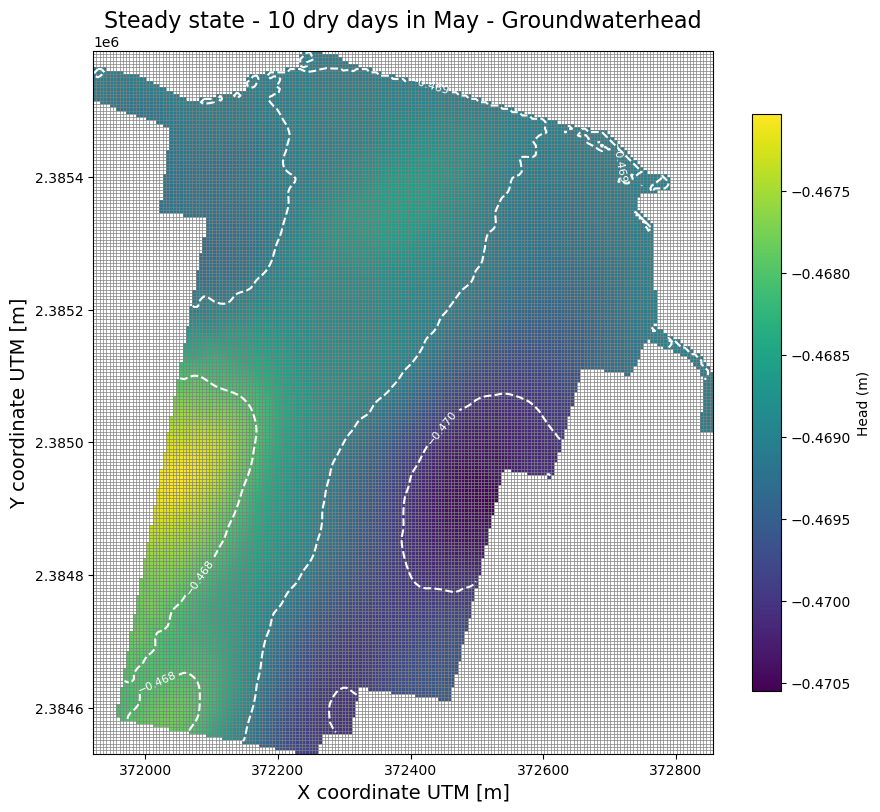

In [29]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, aspect="equal")
pmv = flopy.plot.PlotMapView(model=gwf, ax=ax, layer=0)
pmv.plot_grid(colors="gray", lw=0.5)
map_head = pmv.plot_array(heads_steady, cmap="viridis")
plt.colorbar(map_head, shrink=0.75, label="Head (m)")
contours = pmv.contour_array(heads_steady, levels=3, colors="white")
plt.clabel(contours, inline=True, fontsize=8)
plt.title("Steady state - 10 dry days in May - Groundwaterhead", fontsize=16)
plt.xlabel('X coordinate UTM [m]', fontsize=14)
plt.ylabel('Y coordinate UTM [m]', fontsize=14)
plt.show()

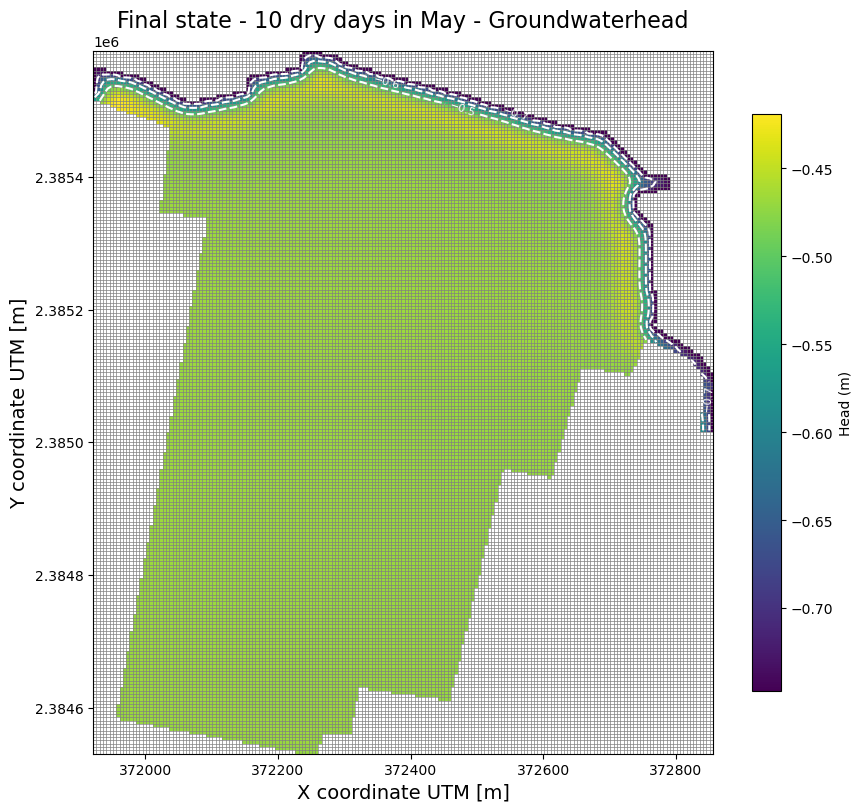

In [30]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, aspect="equal")
pmv = flopy.plot.PlotMapView(model=gwf, ax=ax, layer=0)
pmv.plot_grid(colors="gray", lw=0.5)
map_head = pmv.plot_array(heads_final, cmap="viridis")
plt.colorbar(map_head, shrink=0.75, label="Head (m)")
contours = pmv.contour_array(heads_final, levels=3, colors="white")
plt.clabel(contours, inline=True, fontsize=8)
plt.title("Final state - 10 dry days in May - Groundwaterhead", fontsize=16)
plt.xlabel('X coordinate UTM [m]', fontsize=14)
plt.ylabel('Y coordinate UTM [m]', fontsize=14)
plt.show()



In [31]:
import matplotlib.colors as mcolors

### Overflow map for final state (after 10 days)

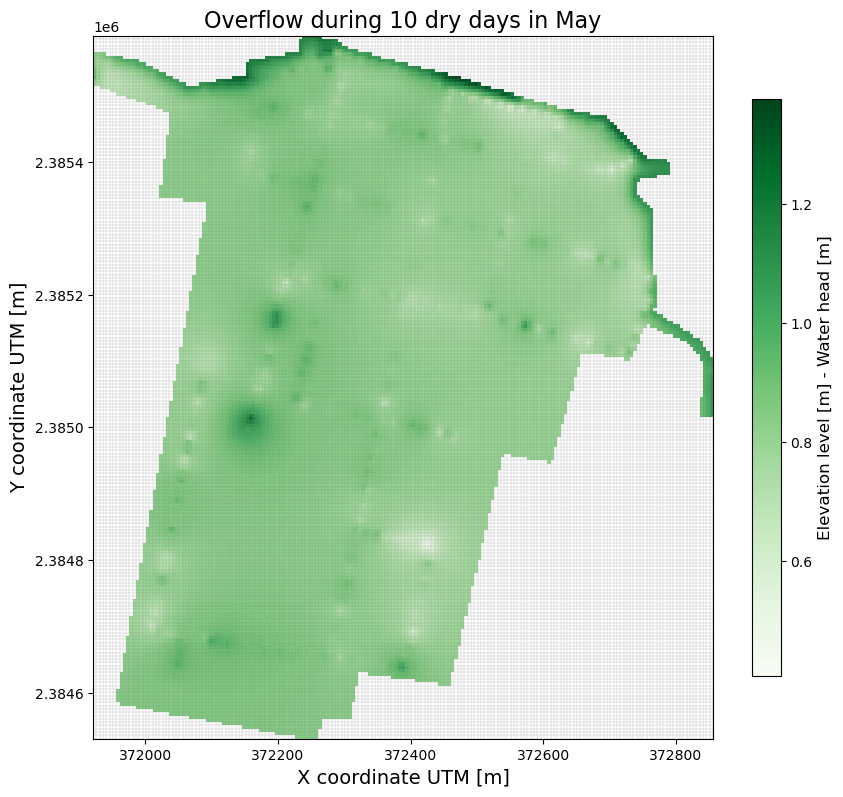

vmin is 0.408 en vmax is 1.376


In [32]:

top_elev = np.round(gwf.dis.top.array, 3)
head_layer1 = np.round(heads_final[0], 3)
depth_to_water = top_elev - head_layer1
depth_to_water[np.abs(depth_to_water) > 1e4] = np.nan
is_flooded = head_layer1 >= top_elev
colors = ["darkred", "red", "lightcoral", "white", "lightgreen", "green", "darkgreen"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("red_green_dtw", colors)
vmin = np.nanmin(depth_to_water)
vmax = np.nanmax(depth_to_water)
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=vmin + 0.5*(vmax-vmin), vmax=vmax)
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, aspect="equal")
pmv = flopy.plot.PlotMapView(model=gwf, ax=ax, layer=0)
pmv.plot_grid(colors="gray", lw=0.3, alpha=0.5)

dtw_plot = pmv.plot_array(depth_to_water, cmap="Greens", norm=norm)
cb = plt.colorbar(dtw_plot, shrink=0.75)
cb.set_label('Elevation level [m] - Water head [m]', fontsize=12)
plt.title("Overflow during 10 dry days in May", fontsize=16)
plt.xlabel('X coordinate UTM [m]', fontsize=14)
plt.ylabel('Y coordinate UTM [m]', fontsize=14)
plt.show()

print(f'vmin is {vmin} en vmax is {vmax}')

In [33]:
import matplotlib.colors as mcolors

In [34]:
idomain_layer1 = gwf.dis.idomain.array[0]

active_mask = (idomain_layer1 > 0) & (~np.isnan(top_elev))
flooded_mask = active_mask & (depth_to_water < 0.0)

rows, cols = np.where(flooded_mask)

grid = gwf.modelgrid


df_flooded = pd.DataFrame({
    "Row": rows,
    "Column": cols,
    "X": grid.xcellcenters[rows, cols],
    "Y": grid.ycellcenters[rows, cols],
    "Flood_Depth_m": np.abs(depth_to_water[rows, cols]),
    "Top_Elev_m": top_elev[rows, cols],
    "Head_m": head_layer1[rows, cols],
})

print(f"Aantal overstroomde cellen BINNEN studiegebied: {len(df_flooded)}")
print(df_flooded.to_string(index=False))

Aantal overstroomde cellen BINNEN studiegebied: 0
Empty DataFrame
Columns: [Row, Column, X, Y, Flood_Depth_m, Top_Elev_m, Head_m]
Index: []


### Observation points
A plot is made for heads over time for the different observation points

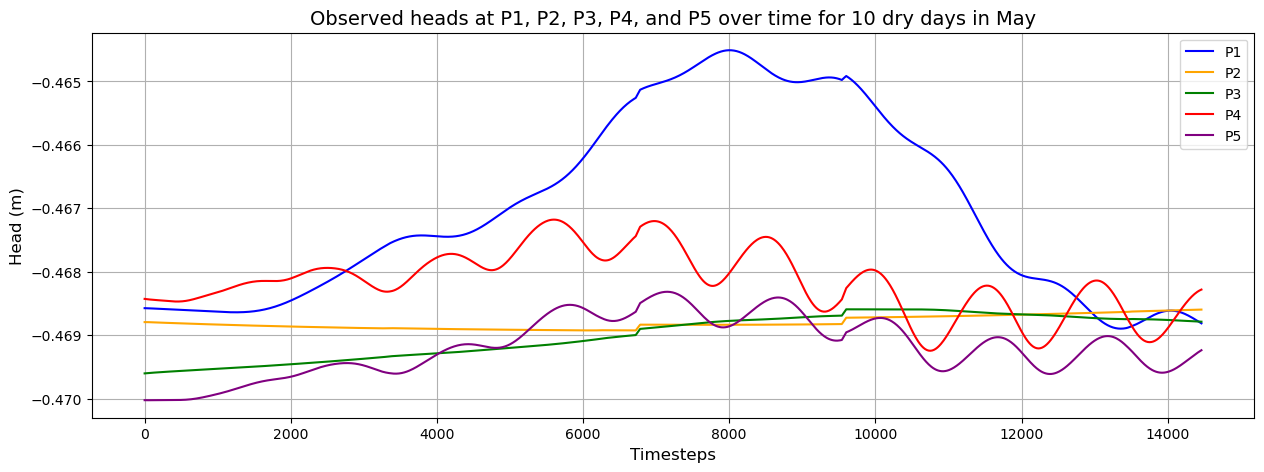

In [35]:
ob = pd.read_csv(r"C:\SAN_FELIPE\SAN_FELIPE\model_dry\SAN_FELIPE.ob_gw_out_head.csv")


plt.figure(figsize=(15, 5))

plt.plot(ob["time"], ob["P1"], label="P1", color ='blue')
plt.plot(ob["time"], ob["P2"], label="P2", color ='orange')
plt.plot(ob["time"], ob["P3"], label="P3", color='green')
plt.plot(ob["time"], ob["P4"], label="P4", color='red')
plt.plot(ob["time"], ob["P5"], label="P5", color='purple')

plt.title("Observed heads at P1, P2, P3, P4, and P5 over time for 10 dry days in May", fontsize=14)
plt.xlabel("Timesteps", fontsize=12)
plt.ylabel("Head (m)", fontsize=12)
plt.legend()
plt.grid(True)

output_folder = r"C:\MDP\Figuren MODFLOW\Dry"
output_path = os.path.join(output_folder, "observationpoints_may_2023.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

         time        P1        P2        P3        P4        P5
0         1.0 -0.468575 -0.468795 -0.469604 -0.468429 -0.470026
1        13.0 -0.468576 -0.468795 -0.469602 -0.468431 -0.470026
2        25.0 -0.468576 -0.468795 -0.469601 -0.468433 -0.470027
3        37.0 -0.468577 -0.468795 -0.469600 -0.468434 -0.470027
4        49.0 -0.468577 -0.468796 -0.469599 -0.468436 -0.470027
...       ...       ...       ...       ...       ...       ...
1201  14413.0 -0.468780 -0.468599 -0.468786 -0.468312 -0.469274
1202  14425.0 -0.468789 -0.468599 -0.468786 -0.468303 -0.469265
1203  14437.0 -0.468797 -0.468598 -0.468787 -0.468295 -0.469255
1204  14449.0 -0.468806 -0.468598 -0.468788 -0.468288 -0.469247
1205  14461.0 -0.468815 -0.468598 -0.468788 -0.468282 -0.469238

[1206 rows x 6 columns]


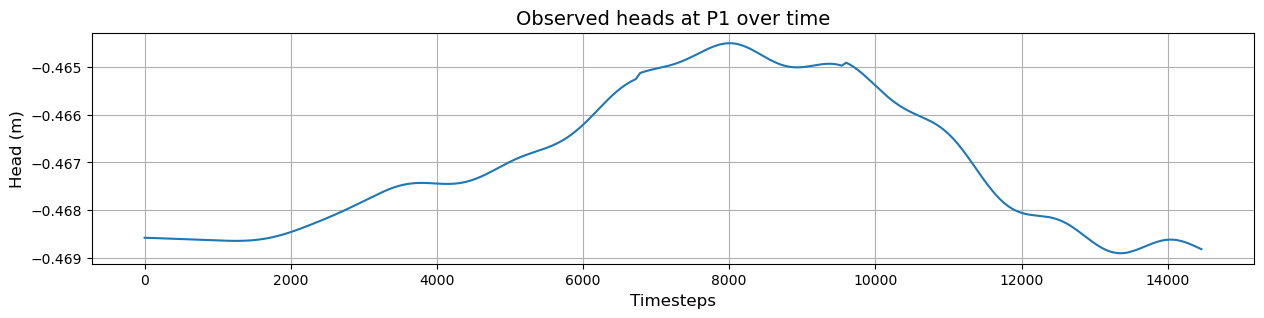

In [37]:
ob = pd.read_csv('C:\SAN_FELIPE\SAN_FELIPE\model_dry\SAN_FELIPE.ob_gw_out_head.csv')
plt.figure(figsize=(15, 3))
plt.plot(ob['time'], ob['P1'], label='P1')
plt.title('Observed heads at P1 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()
print(ob)
                            

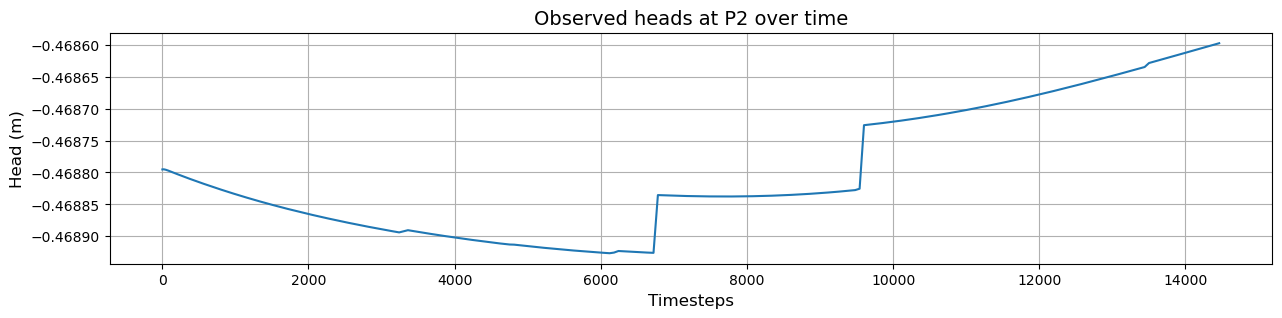

In [38]:
plt.figure(figsize=(15, 3))
plt.plot(ob['time'], ob['P2'])
plt.title('Observed heads at P2 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()

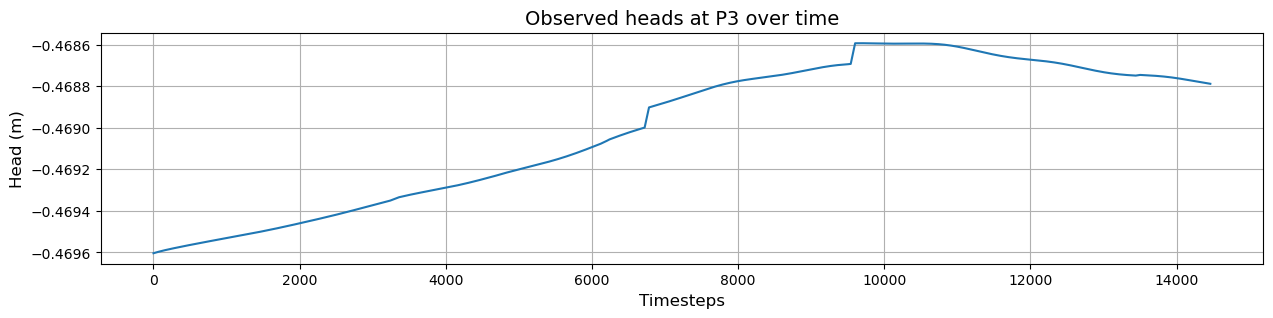

In [39]:
plt.figure(figsize=(15, 3))
plt.plot(ob['time'], ob['P3'])
plt.title('Observed heads at P3 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()

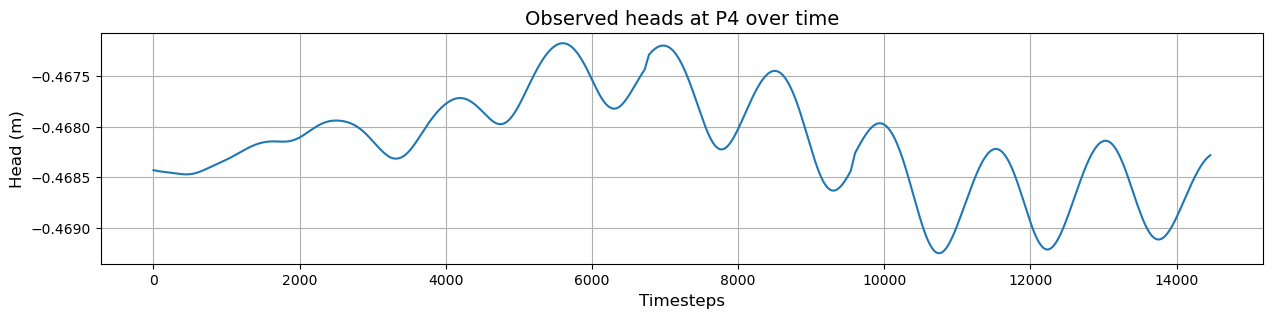

In [40]:
plt.figure(figsize=(15, 3))
plt.plot(ob['time'], ob['P4'])
plt.title('Observed heads at P4 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()

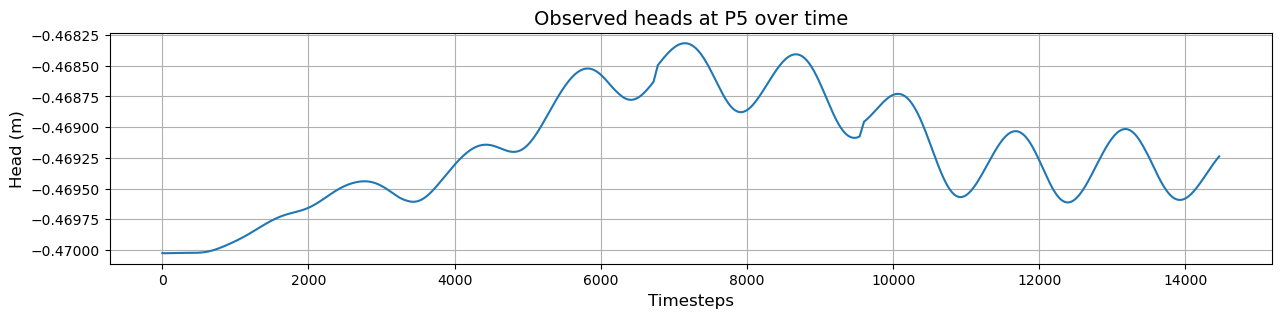

In [41]:
plt.figure(figsize=(15, 3))
plt.plot(ob['time'], ob['P5'])
plt.title('Observed heads at P5 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()
